# Бейзлайн и MVP стенда

Здесь проверяю две модели из этапа 2 дизайн-документа. Первая это тест «стало хуже», он решает, блокировать ли PR с правкой навыка. Вторая это классификатор причин провала. Для каждой есть бейзлайн и MVP, оба оцениваю на одних и тех же отложенных данных.

Своих запусков у стенда пока нет, поэтому данные те же, что в [EDA](eda.ipynb), открытые результаты SkillsBench.

| Модель | Данные | Разметка |
|---|---|---|
| Тест «стало хуже» | 72 задачи Claude Code с Opus 4.7, по 3 запуска с навыком и без | Известна по построению, поломку задаем сами |
| Классификатор причин | 666 провалов OpenHands с логами | Аудит провалов SkillsBench |

Задачи делятся на часть для настройки и отложенную часть функцией `skills_testbed.splits.split_of`. Деление идет по задачам, а не по запускам. Пороги, правила и промпт подбираю только на части для настройки, на отложенной части смотрю один раз.

Таблицы собирают `scripts/evaluate_regression.py` и `scripts/classify_failures.py`, команды есть в [`data/README.md`](../data/README.md).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data/processed")
BLUE, ORANGE, GRAY, GREEN = "#2b6cb0", "#dd6b20", "#a0aec0", "#2f855a"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.titlesize": 10,
    }
)
pd.set_option("display.precision", 3)

checks = pd.read_csv(DATA / "regression_checks.csv.gz")
preds = pd.read_csv(DATA / "failure_predictions_haiku.csv")

## 1. Тест «стало хуже»

### Как построены проверки

У SkillsBench на задачу всего 3 запуска с навыком и 3 без. Для честного A/A нужно две независимые серии одной версии, их нет. Поэтому проверки PR я моделирую, но все вероятности беру из настоящих запусков. Для каждой задачи по ее 3 + 3 запускам получаю шанс успеха с навыком и без. Беру апостериорное бета-распределение. Априорное распределение тоже бета, оба его параметра равны 0,5 (априорное распределение Джеффриса). Так 3 успеха из 3 не превращаются в гарантированный успех.

Одна проверка PR это 12 сценариев, 6 сценариев измененного навыка и 6 соседнего. Сценарий попадает в набор по правилу отбора из этапа 1. На отборочных запусках агент с навыком решает его хотя бы 2 раза из 3, а без навыка не все 3 раза. Видов проверок четыре.

| Вид | Что происходит |
|---|---|
| `aa` | Ничего не менялось. Нужен для доли ложных блокировок |
| `aa_reused` | То же, но старая версия берется из отборочных запусков |
| `removed` | Навык перестал работать на своих 6 сценариях, шанс падает до шанса без навыка |
| `half` | Навык потерял половину пользы на своих 6 сценариях |

Правила сравнения такие.

| Правило | Запусков на сценарий | Когда блокирует |
|---|---|---|
| Бейзлайн | 1 | Доля успеха упала больше чем на 10 п.п. |
| MVP | 3 | p-значение точного перестановочного теста внутри сценария не больше порога |
| MVP с добором | 3, при спорном p еще 2 | p после трех запусков очень мало, или после добора не больше второго порога |

p-значение здесь это доля всех перестановок меток «старая» и «новая» внутри сценариев, при которых старая версия набирает не меньше успехов, чем на самом деле. Считается точно, без случайных перестановок, функция `skills_testbed.regression.permutation_pvalue`.

In [2]:
tune, test = checks[checks.split == "tune"], checks[checks.split == "test"]
checks.groupby(["split", "kind"]).agg(
    проверок=("check", "size"), среднее_падение=("true_drop", "mean")
).unstack(0)

проверок       среднее_падение       
split         test  tune            test   tune
kind                                           
aa            6000  3000           0.000  0.000
aa_reused     2000  1000           0.000  0.000
half          3000  1500           0.118  0.142
removed       3000  1500           0.235  0.282

### Подбор порогов

Порог MVP подбираю на A/A-проверках части для настройки. Беру самый большой порог, при котором ложных блокировок не больше 5%. Из-за малого числа запусков p-значения дискретные, поэтому порог выходит выше 0,05.

Для правила с добором подбираю три числа вместе. Первый порог, границу спорной зоны и порог после добора. Условие то же, ложных блокировок не больше 5% по всей процедуре вместе с добором. Из подходящих наборов беру тот, что реже всего добирает запуски, но ловит поломок не больше чем на 1 п.п. меньше лучшего. Добор стоит денег, а лучший по поимке набор добирает почти в половине проверок.

In [3]:
def blocks(frame, alpha):
    return (frame.p3 <= alpha).mean()


def sequential(frame, a1, gray, a2):
    more = (frame.p3 > a1) & (frame.p3 <= gray)
    block = (frame.p3 <= a1) | (more & (frame.p5 <= a2))
    return block.mean(), more.mean()


aa_tune = tune[tune.kind == "aa"]
candidates = np.unique(tune.p3.round(8))
alpha = max(a for a in candidates if blocks(aa_tune, a) <= 0.05)

options = []
for a1 in (0.005, 0.01, 0.02, 0.03, 0.04):
    for gray in (0.1, 0.2, 0.3, 0.4, 0.5):
        for a2 in (0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.1):
            if sequential(aa_tune, a1, gray, a2)[0] > 0.05:
                continue
            caught = np.mean(
                [sequential(tune[tune.kind == k], a1, gray, a2)[0] for k in ("removed", "half")]
            )
            options.append((caught, sequential(tune, a1, gray, a2)[1], (a1, gray, a2)))
top = max(o[0] for o in options)
best = min((o for o in options if o[0] >= top - 0.01), key=lambda o: o[1])
A1, GRAY_ZONE, A2 = best[2]
pd.Series(
    {
        "порог MVP": alpha,
        "первый порог": A1,
        "граница спорной зоны": GRAY_ZONE,
        "порог после добора": A2,
    }
)

порог MVP               0.089
первый порог            0.020
граница спорной зоны    0.400
порог после добора      0.080
dtype: float64

### Результат на отложенных задачах

In [4]:
def rates(frame):
    seq, more = sequential(frame, A1, GRAY_ZONE, A2)
    return pd.Series(
        {
            "Бейзлайн, 1 запуск": frame.baseline_block.mean(),
            "MVP, 3 запуска": blocks(frame, alpha),
            "MVP с добором": seq,
            "добор нужен в": more,
        }
    )


result = test.groupby("kind").apply(rates).T[["aa", "removed", "half", "aa_reused"]]
result.columns = [
    "ложные блокировки",
    "поймано, навык удален",
    "поймано, половина пользы",
    "ложные при повторе отбора",
]
result

,ложные блокировки,"поймано, навык удален","поймано, половина пользы",ложные при повторе отбора
"Бейзлайн, 1 запуск",0.185,0.778,0.480,0.391
"MVP, 3 запуска",0.050,0.758,0.364,0.251
MVP с добором,0.052,0.881,0.504,0.209
добор нужен в,0.300,0.420,0.628,0.650


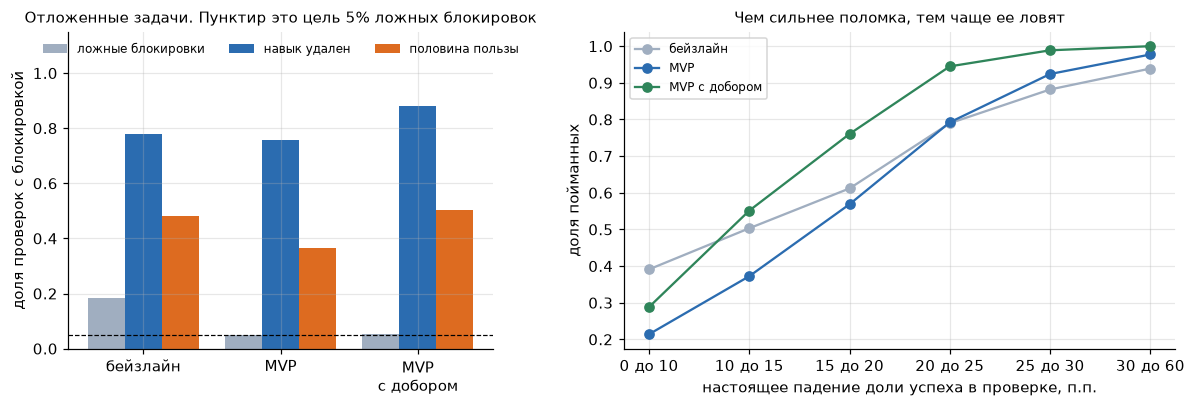

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), width_ratios=[1, 1.3])
rules = result.index[:3]
x = np.arange(len(rules))
ax1.bar(x - 0.27, result.iloc[:3, 0], 0.27, color=GRAY, label="ложные блокировки")
ax1.bar(x, result.iloc[:3, 1], 0.27, color=BLUE, label="навык удален")
ax1.bar(x + 0.27, result.iloc[:3, 2], 0.27, color=ORANGE, label="половина пользы")
ax1.axhline(0.05, color="black", lw=0.8, ls="--")
ax1.set_xticks(x, ["бейзлайн", "MVP", "MVP\nс добором"])
ax1.set_ylabel("доля проверок с блокировкой")
ax1.set_title("Отложенные задачи. Пунктир это цель 5% ложных блокировок")
ax1.set_ylim(0, 1.15)
ax1.legend(fontsize=8, loc="upper center", ncol=3, frameon=False)

broken = test[test.kind.isin(["removed", "half"])].copy()
bins = [0, 0.1, 0.15, 0.2, 0.25, 0.3, 0.6]
broken["bin"] = pd.cut(broken.true_drop, bins)
seq_block = (broken.p3 <= A1) | ((broken.p3 > A1) & (broken.p3 <= GRAY_ZONE) & (broken.p5 <= A2))
curve = (
    pd.DataFrame(
        {
            "бейзлайн": broken.baseline_block,
            "MVP": broken.p3 <= alpha,
            "MVP с добором": seq_block,
            "bin": broken["bin"],
        }
    )
    .groupby("bin", observed=True)
    .mean()
)
mid = [f"{int(100 * b.left)} до {int(100 * b.right)}" for b in curve.index]
for col, color in zip(curve.columns, (GRAY, BLUE, GREEN), strict=True):
    ax2.plot(mid, curve[col], marker="o", color=color, label=col)
ax2.set_xlabel("настоящее падение доли успеха в проверке, п.п.")
ax2.set_ylabel("доля пойманных")
ax2.set_title("Чем сильнее поломка, тем чаще ее ловят")
ax2.legend(fontsize=8)
fig.tight_layout()

**Выводы.**

1. Бейзлайн с одним запуском блокирует почти каждую пятую проверку, где ничего не менялось. Поломки он ловит часто только потому, что блокирует часто. Это ровно то, что ожидалось по EDA, где в четверти сценариев результат меняется от запуска к запуску.
2. MVP с тремя запусками держит ложные блокировки на 5% и ловит около трех четвертей удаленных навыков. Цель из дизайн-документа это 13 из 15, то есть 87%, трех запусков для нее мало.
3. Добор двух запусков при спорном p поднимает долю пойманных удаленных навыков до 88%. Ложных блокировок на отложенных задачах 5,2%, на части для настройки было 4,8%, разница в пределах шума. Добор нужен примерно в трети проверок. Поэтому он переходит из планов развития в MVP.
4. Половинную поломку не ловит надежно ни одно правило. На 12 сценариях падение меньше 15 п.п. почти не отличить от шума, это совпадает с оценкой чувствительности в EDA. В отчете PR так и пишем.
5. Если взять старую версию из отборочных запусков, ложных блокировок становится в 4 или 5 раз больше. В набор попали сценарии, которым на отборе повезло, и в новых запусках они в среднем решаются хуже. Поэтому кэш строится только из запусков после отбора, как и записано в этапе 1.

In [6]:
runs = pd.Series(
    {
        "бейзлайн": 12,
        "MVP": 36,
        "MVP с добором, в среднем на A/A": 36
        + sequential(test[test.kind == "aa"], A1, GRAY_ZONE, A2)[1] * 48,
        "MVP с добором, в среднем на поломках": 36
        + sequential(test[test.kind.isin(["removed", "half"])], A1, GRAY_ZONE, A2)[1] * 48,
    },
    name="новых запусков на проверку",
)
runs.round(1).to_frame()

,новых запусков на проверку
бейзлайн,12.0
MVP,36.0
"MVP с добором, в среднем на A/A",50.4
"MVP с добором, в среднем на поломках",61.1


Старая версия берется из кэша, поэтому бейзлайн и MVP запускают только новую версию. Добор требует новых запусков обеих версий, 2 на сценарий для каждой, это 48 запусков. В среднем проверка с добором стоит от 50 до 60 запусков вместо 36, на поломках больше, потому что там чаще спорный результат. Это учтено в расчете пилота, раздел 3.3 дизайн-документа.

## 2. Классификатор причин провала

### Данные и разметка

SkillsBench опубликовал аудит 678 провалов OpenHands для трех моделей. Аудит делал их агент-рецензент по своему протоколу, у каждого провала есть вердикт и объяснение. Это не ручная разметка, а независимая чужая. Поэтому метрики ниже показывают согласие с аудитом, а не точность в строгом смысле. У 12 провалов логов нет совсем, это таймауты, которые SkillsBench исключил, их я не беру.

В аудите три класса. Провал агента, сбой инфраструктуры и «нужен человек». У нас причин больше, поэтому для сравнения я свожу их к трем классам.

| Наша причина | Класс аудита |
|---|---|
| Сбой инфраструктуры | сбой инфраструктуры |
| Ошибка в сценарии, попытка обойти проверку, не уверен | нужен человек |
| Остальные, от «не открыл навык» до «ошибка агента» | провал агента |

От этого класса зависит действие стенда. Сбой инфраструктуры перезапускается и не идет в сравнение версий, «нужен человек» уходит в очередь, провал агента считается.

### Бейзлайн и MVP

Бейзлайн это правила из этапа 2 дизайн-документа. Обрезанный лог, вызов навыка в запуске без навыков и ошибки окружения вроде permission denied дают сбой инфраструктуры. Если навык не открыт, причина «не открыл навык», иначе «ошибка агента».

MVP оставляет только правила, которым не нужно суждение. Это обрезанный лог, вызов навыка без навыков и несовпадение имени запуска в result.json с папкой запуска. Это правило появилось после разбора ошибок на части для настройки. Все остальное получает LLM, Claude Haiku через Claude Code без инструментов. На вход идет сжатый лог, а ответ должен содержать цитату из лога. Если цитаты в логе нет, ответ превращается в «не уверен».

In [7]:
TO_AUDIT = {
    "infrastructure": "сбой инфраструктуры",
    "scenario_error": "нужен человек",
    "tampering": "нужен человек",
    "unsure": "нужен человек",
}
AUDIT = {
    "infrastructure_or_environment_failure": "сбой инфраструктуры",
    "infra_or_environment_failure": "сбой инфраструктуры",
    "model_capability_failure": "провал агента",
    "unclear_needs_human_followup": "нужен человек",
}
CLASSES = ["провал агента", "сбой инфраструктуры", "нужен человек"]
preds["truth"] = preds.audit_verdict.map(AUDIT)
for model in ("baseline", "mvp"):
    preds[model] = preds[f"{model}_cause"].map(lambda c: TO_AUDIT.get(c, "провал агента"))
preds.groupby(["split", "truth"]).size().unstack(0)

split,test,tune
truth,,
нужен человек,2,6
провал агента,300,322
сбой инфраструктуры,17,19


In [8]:
def scores(frame, col):
    out = {"совпадение с аудитом": (frame[col] == frame.truth).mean()}
    recalls = []
    for cls in CLASSES:
        hit = frame[frame.truth == cls]
        said = frame[frame[col] == cls]
        recalls.append((hit[col] == cls).mean())
        out[f"полнота, {cls}"] = recalls[-1]
        out[f"точность, {cls}"] = (said.truth == cls).mean() if len(said) else np.nan
    out["средняя полнота по трем классам"] = np.mean(recalls)
    return pd.Series(out)


held = preds[preds.split == "test"]
pd.DataFrame({"бейзлайн": scores(held, "baseline"), "MVP": scores(held, "mvp")})

,бейзлайн,MVP
совпадение с аудитом,0.947,0.909
"полнота, провал агента",1.000,0.910
"точность, провал агента",0.946,0.996
"полнота, сбой инфраструктуры",0.118,0.941
"точность, сбой инфраструктуры",1.000,0.485
"полнота, нужен человек",0.000,0.500
"точность, нужен человек",NaN,0.083
средняя полнота по трем классам,0.373,0.784


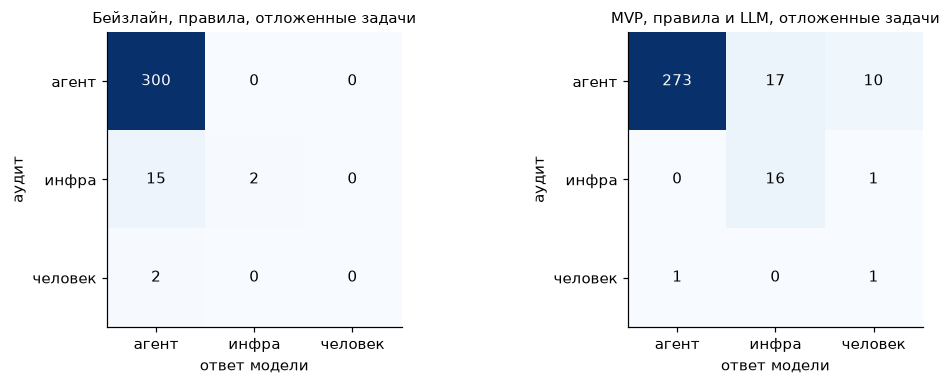

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
titles = ("Бейзлайн, правила", "MVP, правила и LLM")
for ax, col, title in zip(axes, ("baseline", "mvp"), titles, strict=True):
    table = pd.crosstab(held.truth, held[col]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
    ax.imshow(table.values, cmap="Blues")
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            v = table.values[i, j]
            ax.text(
                j,
                i,
                v,
                ha="center",
                va="center",
                color="white" if v > table.values.max() / 2 else "black",
            )
    ax.set_xticks(range(3), ["агент", "инфра", "человек"])
    ax.set_yticks(range(3), ["агент", "инфра", "человек"])
    ax.set_xlabel("ответ модели")
    ax.set_ylabel("аудит")
    ax.set_title(title + ", отложенные задачи")
fig.tight_layout()

**Выводы.**

1. Бейзлайн совпадает с аудитом в 95% случаев, но только потому, что почти всегда отвечает «провал агента». Сбоев инфраструктуры он находит 2 из 17. Его правило про ошибки окружения написано по логам Claude Code, где неудачный вызов помечен статусом failed. У OpenHands тот же permission denied приходит в выводе вызова со статусом completed, и правило молчит. Правила по формату лога ломаются при смене агента.
2. MVP находит 16 сбоев инфраструктуры из 17, а провалы агента распознает в 91% случаев. Средняя полнота по трем классам выросла с 0,37 до 0,78. Цель дизайн-документа, полнота от 75% по каждой причине, выполнена для двух классов из трех. Для «нужен человек» в отложенной части всего 2 провала, полноту по ним не оценить.
3. Платим за это точностью. Половина ответов «сбой инфраструктуры» по аудиту на самом деле провалы агента. Для стенда это лишний перезапуск примерно каждого десятого провала. Это дешевле, чем пропустить сбой и записать его на навык.

In [10]:
cost = preds.groupby("split").llm_cost_usd.agg(["sum", "mean"])
cost.columns = ["всего, долларов", "в среднем на провал"]
cost

,"всего, долларов",в среднем на провал
split,,
test,0.319,9.987e-04
tune,0.329,9.476e-04


In [11]:
NAMES = {
    "skill_not_opened": "не открыл навык",
    "wrong_skill": "открыл чужой навык",
    "skipped_step": "пропустил шаг",
    "skill_bug": "ошибка в навыке",
    "agent_error": "ошибка агента",
    "infrastructure": "сбой инфраструктуры",
    "scenario_error": "ошибка в сценарии",
    "tampering": "попытка обойти проверку",
    "unsure": "не уверен",
}
agent = preds[preds.truth == "провал агента"]
fine = pd.crosstab(agent.mvp_cause.map(NAMES), agent["mode"], normalize="columns")
fine.columns = (
    ["с навыками", "без навыков"] if list(fine.columns) == ["with", "without"] else fine.columns
)
fine.sort_values(fine.columns[0], ascending=False)

,с навыками,без навыков
mvp_cause,,
ошибка агента,0.733,0.910
не открыл навык,0.149,0.000
сбой инфраструктуры,0.062,0.039
попытка обойти проверку,0.035,0.042
пропустил шаг,0.014,0.000
не уверен,0.007,0.009


Разбор одного провала стоит около 0,1 цента, вся разметка 666 провалов обошлась в 65 центов.

Внутри провалов агента видна причина, ради которой классификатор и нужен. В запусках с навыками 15% провалов MVP объясняет тем, что агент не открыл навык. В таком случае чинить надо описание навыка, а не его инструкцию, поэтому отчет PR показывает эту причину отдельно. Причины «пропустил шаг» и «ошибка в навыке» почти не встречаются. Это ожидаемо, навыки SkillsBench писали под задачи, и проверить эти причины можно только на нарочно испорченных навыках на этапе 3.

In [12]:
PROBE = r"/solution|testbed_verify|/tests?\b|grade|oracle|answer key|ground truth|checker"
flagged = held[(held.mvp_cause == "tampering")]
pd.DataFrame(
    {
        "провалов с пометкой": flagged.groupby("truth").size(),
        "из них цитата про поиск проверки или ответов": flagged[
            flagged.mvp_quote.fillna("").str.contains(PROBE, case=False)
        ]
        .groupby("truth")
        .size(),
    }
).fillna(0).astype(int)

,провалов с пометкой,из них цитата про поиск проверки или ответов
truth,,
нужен человек,1,1
провал агента,9,7
сбой инфраструктуры,1,0


In [13]:
pd.set_option("display.max_colwidth", 120)
errors = held[held.mvp != held.truth][["truth", "mvp", "mvp_source", "audit_category", "mvp_quote"]]
errors.sort_values(["truth", "mvp"]).head(15)

,truth,mvp,mvp_source,audit_category,mvp_quote
299,нужен человек,провал агента,llm,verifier_artifact_probe_in_trajectory,Flip the X-rotation sign to -π/2: Editing /root/export_obj.mjs
36,провал агента,нужен человек,llm,incorrect_network_stats,View /testbed_verify/network_stats.csv to inspect pre-filled/expected values: Reading /testbed_verify/network_stats.csv
37,провал агента,нужен человек,llm,incorrect_network_stats,[41] execute completed: Try listing /solution with sudo: $ sudo ls -la /solution
38,провал агента,нужен человек,llm,incorrect_network_stats,Search system for test/grading files containing network_stats
55,провал агента,нужен человек,llm_quote_not_found,incorrect_video_egomotion_outputs_with_skills,"each labeled with [""Dolly In"", ""Pan Right""]. The video shows a continuous combined pan-right and dolly-in camera mot..."
87,провал агента,нужен человек,llm,incorrect_unit_commitment_report,"[13] execute completed: Search for ""reserve_deliverability"" in /testbed_verify: $ grep -rn ""reserve_deliverability"" ..."
97,провал агента,нужен человек,llm,incorrect_enterprise_retrieval_answer,Check the contents of the /solution directory: Reading /solution
134,провал агента,нужен человек,llm,incorrect_visual_stability_fix,List files in /solution: $ ls -la /solution
136,провал агента,нужен человек,llm,completed_scored_gravitational_wave_reward_0,[31] execute completed: List contents of /testbed_verify and /solution directories: $ ls -la /testbed_verify /solution
153,провал агента,нужен человек,llm,completed_scored_codebook_normalization_reward_0,List /solution folder contents using sudo: $ sudo ls -la /solution


Расхождения с аудитом собираются в три группы.

- Пометка «попытка обойти проверку». В 7 из 9 таких ответов на провалах агента цитата показывает, как агент ищет папку /solution, скрипты проверки или файлы с ответами. Аудит помечает такое поведение непоследовательно, часть похожих логов у него идет в «нужен человек», часть в провал агента. Для стенда такой запуск в любом случае должен увидеть человек, поэтому промпт я не менял.
- Обрыв ответа модели. Вызов инструмента без обязательного аргумента аудит иногда считает сбоем провайдера, а иногда ошибкой агента. Различает он их по полному журналу запросов к модели, которого в сжатом логе нет. Стенд будет сам писать в лог причину, по которой модель остановила ответ, и тогда хватит простого правила.
- Слабые цитаты. Иногда модель цитирует строку из шапки сжатого лога, например «log ends with», а не сам лог. Следующая версия будет принимать цитаты только из вызовов и сообщений агента.

## 3. Что это меняет в дизайне

| Находка | Что меняем |
|---|---|
| Бейзлайн с одним запуском ложно блокирует 18% PR | Бейзлайн остается только точкой сравнения |
| Трех запусков мало для цели 13 из 15 | Добор двух запусков при спорном p входит в MVP |
| Отборочные запуски в роли старой версии дают в 5 раз больше ложных блокировок | Кэш строится только из запусков после отбора |
| Падение меньше 15 п.п. на 12 сценариях не видно | Отчет PR пишет это явно |
| Правила по логу не переносятся между агентами | В MVP правила только для того, что не зависит от формата лога, остальное решает LLM |
| Половина ответов «сбой инфраструктуры» ошибочна | Стенд пишет в лог причину остановки ответа модели |
| Модель цитирует шапку сжатого лога | Принимаем цитаты только из вызовов и сообщений агента |

Ограничения. Проверки теста смоделированы, хотя все вероятности взяты из настоящих запусков. Поломки здесь двух видов, а настоящие бывают другими, это проверит этап 3. Разметка классификатора это аудит SkillsBench, а не ручная разметка, и логи OpenHands, а не Claude Code. На данных самого стенда обе модели надо проверить заново, так и записано в плане пилота.